# Reproducing Figure 7A/7B of Higgins et al., *β-VAE* (ICLR 2017) on dSprites

This notebook trains the paper's fully connected VAE on the 2D-shapes (dSprites) data with **β = 4** (Fig. 7A) and **β = 1** (Fig. 7B), then rebuilds both panels from saved run outputs. It was written from the paper alone; no existing implementation was consulted, and only the `.npz` data file from the official dSprites repository is used.

Everything you need to know before running is in the next three text cells: what the paper specifies (with citations), every choice the paper leaves open, and the seed and compute plan. After that the code runs top to bottom. If the kernel dies, restart it and **run all cells again**: finished runs are skipped, a partial run resumes from its last checkpoint, and the compute plan in `plan.json` is reused rather than re-measured.

Section, equation, table and figure numbers refer to the ICLR 2017 PDF.

## 1. What the paper specifies

**Model and optimiser** — Table 1 (Appendix A.1), row *2D shapes (VAE)*:

| Part | Table 1 entry | Implemented as |
|---|---|---|
| Input | 4096 (flattened 64×64×1) | binary pixels as floats in {0, 1} |
| Encoder | FC 1200, 1200. ReLU activation | Linear 4096→1200, ReLU, Linear 1200→1200, ReLU |
| Latents | 10 | Gaussian q(z\|x) = N(μ(x), diag σ²(x)), prior p(z) = N(0, I) (Sec. 2) |
| Decoder | FC 1200, 1200, 1200, 4096. Tanh activation. Bernoulli | Linear 10→1200, Tanh, ×3 hidden layers, Linear 1200→4096 giving Bernoulli logits |
| Optimiser | Adagrad, 1e-2 | `torch.optim.Adagrad(lr=1e-2)` |

The β = 1 baseline uses the identical network: Sec. 4.2 ("the original VAE formulation … (β = 1) with the same architecture as β-VAE") and App. A.4 ("β-VAE (β = 4), VAE (β = 1) and VAE untrained have the same fully connected architecture with ten latent units z").

**Objective** — Sec. 2, Eq. 4: maximise E_q[log p(x|z)] − β·KL(q(z|x) ‖ p(z)); β = 1 is the original VAE. App. A.6, Eq. 7 writes log p(x|z) as a **sum over pixels**, and A.6 defines a separate normalised β_norm = βM/N (used in Fig. 6 right). So the β = 4 of Fig. 7A is the *unnormalised* coefficient on a per-image KL summed over M = 10 latents against a Bernoulli log-likelihood summed over N = 4096 pixels (β_norm = 4·10/4096 ≈ 0.0098).

**Data** — Sec. 4.2: 737,280 binary 64×64 images; three shapes (heart, oval, square) × position X (32) × position Y (32) × scale (6) × rotation (40 values over 2π).

**What Figure 7 shows** — Fig. 7 caption, with the discussion in Sec. 4.2 (pp. 8–9). Panel A is the β-VAE with β = 4; panel B is the "similar analysis for VAE (β = 1)".

* **Columns** are latents, "ordered according to the learnt Gaussian variance (last row)". In the printed figure the values increase left to right (A: 0.08, 0.08, 0.22, 0.50, 0.51, 0.99; B: 0.07, 0.13, 0.18, 0.18, 0.47, 0.99) and each panel shows five latents plus one column labelled *Z_unused*. Sec. 4.2 gives the reason this order is meaningful: informative latents have high KL from the N(0, I) prior, while uninformative ones have KL ≈ 0, i.e. learnt variance ≈ 1.
* **Row 1 (position)**: the mean activation of each latent as a function of all 32×32 locations, averaged across objects, rotations and scales; red is high. "Activation" is the posterior mean: Sec. 4.2 writes the response as z^μ_m = f(v_k), "where z^μ_m is the learnt Gaussian mean of latent unit z_m".
* **Row 2 (scale)**: mean activation versus scale, averaged across rotations and positions, one line per shape.
* **Row 3 (rotation)**: mean activation versus rotation, averaged across scales and positions, one line per shape. Square is red, oval green, heart blue.
* **Rows 4–8 (single latent mean traversal)**: "reconstructions resulting from the traversal of each latent z_i over three standard deviations around the unit Gaussian prior mean while keeping the remaining 9/10 latent units fixed to the values obtained by running inference on an image from the dataset". Fig. 1's caption, which applies to "all figures of latent code traversal", gives the range as [−3, 3] with the other latents at their inferred values. The axis drawn beside Fig. 7 runs from +3 (top) through 0 to −3 (bottom) across the five rows.
* **Last row**: the learnt variance used for the ordering. The words under it (pos. Y, pos. X, scale, rotation) are the authors' interpretations, discussed in Sec. 4.2.

## 2. Choices the paper leaves unspecified (all in one place)

| # | Choice | What the paper says | This notebook |
|---|---|---|---|
| U1 | Minibatch size | not stated | 64 |
| U2 | Training length and stopping rule | not stated | the same fixed number of steps for every run, chosen by the budget benchmark in §5 (target 300,000 steps ≈ 26 epochs; at least 150,000 to keep 3 seeds); the final checkpoint is analysed, with no early stopping or checkpoint picking |
| U3 | Adagrad settings besides the learning rate | not stated | PyTorch defaults: initial accumulator 0, ε = 1e-10, no learning-rate decay, no weight decay |
| U4 | Weight initialisation | not stated | PyTorch default `nn.Linear` initialisation |
| U5 | Encoder output head | "Latents 10" only | one linear layer 1200→20 producing μ and log σ² |
| U6 | Posterior samples per image per step | not stated | 1 (reparameterisation trick) |
| U7 | Loss reduction over the minibatch | per-image sums implied by Eq. 7 / A.6; batch reduction not stated | mean over the minibatch of the per-image loss |
| U8 | Data order and train/test split | not stated; Fig. 7 is computed on the dataset itself | train on all 737,280 images, reshuffled every epoch with a seeded permutation; no held-out split |
| U9 | Numerical precision | not stated | FP32 with TF32 disabled |
| U10 | The statistic called "learnt variance" | "learnt Gaussian variance" | mean of σ²_m(x) over all 737,280 images |
| U11 | Images averaged in rows 1–3 | "averaged across objects, rotations and scales" | the full dataset, which is a balanced Cartesian product, so these are exact marginal means |
| U12 | Which latents get a column; how unused ones are shown | 5 latents + one *Z_unused* column, no rule given | **paper layout**: the 5 lowest-variance latents plus the single highest-variance latent, labelled with its real index and variance; a **full 10-latent version** of every panel is also drawn so nothing is hidden |
| U13 | Image that seeds the traversal | "an image from the dataset" | one fixed ellipse (shape = ellipse, scale index 3, orientation index 8, posX index 10, posY index 14), the same image for every β and seed; both printed panels appear to use an oval, but the paper doesn't say which image |
| U14 | Traversal grid | ±3 SD, five rows | five evenly spaced values +3, +1.5, 0, −1.5, −3, top to bottom |
| U15 | "Inferred values" of the fixed latents: mean or sample | not stated | posterior mean μ(x), as the paper's metric also uses μ (Sec. 3, step 2b) |
| U16 | What a traversal cell displays | "reconstructions" | the Bernoulli mean sigmoid(logits), not a sample |
| U17 | Colour scale of the position maps; y-limits of the line plots | "red represents high values" | jet colormap; within a panel all columns share one symmetric range [−a, a] (so 0 is green); line plots share symmetric y-limits within each row of a panel |
| U18 | Orientation of the 32×32 position map | not stated | arranged so each cell sits where the object appears in the image; the mapping from the posX/posY columns to image rows/columns is measured from the data, not assumed |
| U19 | Which replica is shown, and how many were trained | not stated for Fig. 7 (the metric in Fig. 6 used 10 replicas with the bottom 50% discarded, App. A.4) | seed 0 is fixed in advance as the main figure, and every seed is plotted |
| U20 | Factor labels under the columns | hand-written interpretations | replaced by a data-derived annotation: the factor explaining the largest share of the variance of the latent's mean response (balanced-ANOVA main effect; "rotation" includes its interaction with shape, because the symmetry period differs per shape, Sec. 4.2). Latents with mean KL below 0.01 nats are marked "inactive". **This annotation is my addition, not the paper's** |
| U21 | Framework, seeding, hardware | not stated | PyTorch; seeds for Python, NumPy and torch; a seeded per-epoch data permutation; a seeded generator for the reparameterisation noise, saved in every checkpoint |

Two smaller details are read from the data rather than assumed: the shape names behind dSprites' shape codes (checked by rotational symmetry in §3) and the scale and rotation values on the x-axes of rows 2–3 (taken from `latents_values`).

## 3. Seeds, compute plan and run order

**Seeds.** The plan is **3 seeds per β (seeds 0, 1, 2), 6 runs**, if the benchmark in §5 shows they fit in the training share of the budget (75 of the 90 GPU-minutes; the rest covers loading data, the benchmark, analysis and plotting). The rule, written down before any run:

1. If 6 runs × 300,000 steps fit, train 3 seeds at 300,000 steps.
2. Otherwise, if 6 runs fit at ≥ 150,000 steps, train 3 seeds at the largest step count that fits.
3. Otherwise drop to **2 seeds per β** at up to 300,000 steps. Reason: an under-trained β = 4 run says nothing about the paper's claim, while a third seed only refines the estimate of seed-to-seed spread, so length takes priority over the third seed. If even 2 seeds can't reach 150,000 steps, the plan falls back to 1 seed per β and says so.

The decision and the measured step time are written to `plan.json` before training starts, and every run uses the same step count.

**What 3 seeds can show:** whether the qualitative pattern in Fig. 7 recurs across independent initialisations and data orders — for β = 4, a handful of low-variance latents each tied to one factor with the rest near σ² = 1; for β = 1, latents that respond to several factors at once — and a first look at how much the learnt variances move between seeds.

**What 3 seeds cannot show:** a failure rate or a significance test. If all 3 β = 4 seeds disentangle, the data are still consistent with a per-seed success rate as low as 37% (one-sided 95% bound, 0.05^(1/3)). If β = 4 failed in 1 of every 5 seeds, there's a 51% chance (0.8³) that none of 3 seeds would show it. The paper itself trained 10 replicas for its quantitative results and discarded the worst half (App. A.4); this notebook does not compute the disentanglement metric at all.

**Run order** (so a usable figure exists early): β = 4 seed 0, β = 1 seed 0 → **Fig. 7A/B from seed 0** → β = 4 seed 1, β = 1 seed 1, β = 4 seed 2, β = 1 seed 2 → all-seed figures. Seed 0 is fixed in advance as the main figure, whichever seed looks best.

**Pre-stated reading of the result.** Fig. 7A is reproduced if the β = 4 panel shows a few low-variance latents whose position maps are single-axis gradients (one horizontal, one vertical), one latent with monotonic scale curves, and two latents whose rotation curves oscillate with a period that depends on the shape, while the remaining latents sit near σ² ≈ 1 with flat responses. Fig. 7B is reproduced if the β = 1 panel shows latents whose position maps are blob-like and whose responses mix several factors (Sec. 4.2: "each latent z (apart from z9, which learnt rotation) encodes at least two data generative factors").

**Resuming.** Each run checkpoints model, optimiser, step counter and RNG state every 20,000 steps by atomic write, so an interruption costs at most 20,000 steps. A run that produces non-finite loss is marked `FAILED.json`, reported, and left out of the figures rather than silently replaced; delete that file to retry it.

## 4. Setup

In [1]:
import os
# Must be set before CUDA is initialised so cuBLAS runs deterministically.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json, math, time, random, platform
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cuda.matmul.allow_tf32 = False   # U9: plain FP32
torch.backends.cudnn.allow_tf32 = False

# ---- paths (change DSPRITES_PATH to wherever you saved the official .npz) ----
DSPRITES_PATH = Path(os.environ.get("DSPRITES_PATH", "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"))
RUN_ROOT = Path(os.environ.get("FIG7_RUN_ROOT", "runs_fig7"))
FIG_DIR = RUN_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- specified by the paper ----
INPUT_DIM  = 64 * 64              # Table 1: "Input 4096 (flattened 64x64x1)"
ENC_HIDDEN = (1200, 1200)         # Table 1: "Encoder FC 1200, 1200. ReLU activation."
LATENT_DIM = 10                   # Table 1: "Latents 10"; App. A.4: "ten latent units z"
DEC_HIDDEN = (1200, 1200, 1200)   # Table 1: "Decoder FC 1200, 1200, 1200, 4096. Tanh activation. Bernoulli."
LR         = 1e-2                 # Table 1: "Adagrad 1e-2"
BETAS      = (4.0, 1.0)           # Fig. 7 caption: A = beta-VAE (beta = 4), B = VAE (beta = 1)
TRAVERSAL_VALUES = np.linspace(3.0, -3.0, 5)   # Fig. 7 caption / Fig. 1 caption: +-3 around the prior mean; 5 rows, +3 on top (U14: even spacing)

# ---- not specified by the paper (see table in section 2) ----
BATCH_SIZE = 64                                                        # U1
DEFAULT_STEPS = int(os.environ.get("FIG7_DEFAULT_STEPS", 300_000))     # U2
MIN_STEPS_FOR_3_SEEDS = int(os.environ.get("FIG7_MIN_STEPS", 150_000)) # U2 / seed plan
LOG_EVERY  = int(os.environ.get("FIG7_LOG_EVERY", 1_000))
CKPT_EVERY = int(os.environ.get("FIG7_CKPT_EVERY", 20_000))
SEEDS_WANTED = (0, 1, 2)
GPU_BUDGET_MIN   = float(os.environ.get("FIG7_GPU_BUDGET_MIN", 130))    # your total budget
TRAIN_BUDGET_MIN = float(os.environ.get("FIG7_TRAIN_BUDGET_MIN", 110))  # share reserved for training
SAFETY = 1.10            # inflate measured step time by 10% for logging, checkpointing, clock drift
BENCH_WARMUP = int(os.environ.get("FIG7_BENCH_WARMUP", 200))
BENCH_STEPS  = int(os.environ.get("FIG7_BENCH_STEPS", 1_000))
MAIN_FIGURE_SEED = 0     # U19: fixed before training
TRAVERSAL_SEED_IMAGE = dict(shape="ellipse", scale=3, orientation=8, posX=10, posY=14)  # U13 (factor indices)
KL_INACTIVE_NATS = 0.01  # U20: only affects the text annotation under each column
SHAPE_COLORS = {"square": "red", "ellipse": "green", "heart": "blue"}  # Fig. 7 caption

assert CKPT_EVERY % LOG_EVERY == 0, "checkpoints must land on logging steps"
print(f"device={DEVICE}  torch={torch.__version__}  python={platform.python_version()}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device=cuda  torch=2.14.1+cu130  python=3.13.12
GPU: NVIDIA GeForce RTX 3080 Ti


## 5. Data

Only the official `.npz` is used. The checks below confirm the dataset matches Sec. 4.2 (size, factor counts, binary pixels, a full Cartesian product), identify which shape code is which shape from the images themselves, and measure which way posX and posY move the object so the position maps in row 1 can be drawn in image orientation. The results are saved to `dataset_info.json`.

In [2]:
def load_dsprites(path):
    # The metadata entry is a pickled dict written by Python 2, hence allow_pickle + latin1.
    d = np.load(path, allow_pickle=True, encoding="latin1")
    imgs = d["imgs"]
    classes = d["latents_classes"].astype(np.int64)
    values = d["latents_values"].astype(np.float64)
    names = ("color", "shape", "scale", "orientation", "posX", "posY")  # column order documented with the dataset
    try:
        meta = d["metadata"][()]
        raw = meta["latents_names"]
        names = tuple(n.decode() if isinstance(n, bytes) else str(n) for n in raw)
        print("factor names from metadata:", names)
    except Exception as e:
        print("metadata not readable; using the documented column order:", names, f"({e})")
    return imgs, classes, values, names

t_load = time.perf_counter()
imgs_np, CLASSES, VALUES, FACTOR_NAMES = load_dsprites(DSPRITES_PATH)
COL = {n: i for i, n in enumerate(FACTOR_NAMES)}
SIZES = {n: int(CLASSES[:, i].max() + 1) for n, i in COL.items()}
N_IMAGES = imgs_np.shape[0]
print(f"loaded {N_IMAGES:,} images of shape {imgs_np.shape[1:]} in {time.perf_counter() - t_load:.1f}s")
print("factor sizes:", SIZES)

# --- checks against Sec. 4.2 ---
assert imgs_np.dtype == np.uint8 and imgs_np.shape[1:] == (64, 64)
assert imgs_np.max() <= 1, "pixels are expected to be binary {0,1}"
expected = {"shape": 3, "scale": 6, "orientation": 40, "posX": 32, "posY": 32}
for k, v in expected.items():
    if SIZES[k] != v:
        print(f"WARNING: {k} has {SIZES[k]} values, Sec. 4.2 says {v}")
if N_IMAGES != 737_280:
    print(f"WARNING: {N_IMAGES} images, Sec. 4.2 says 737,280")
flat_ids = np.ravel_multi_index(CLASSES.T, tuple(SIZES[n] for n in FACTOR_NAMES))
assert np.unique(flat_ids).size == N_IMAGES == int(np.prod(list(SIZES.values()))), "not a full Cartesian product"
print("checks passed: binary 64x64 images, full Cartesian product of the factors")

c:\Users\Tyler\miniconda3\Lib\site-packages\numpy\lib\_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


factor names from metadata: ('color', 'shape', 'scale', 'orientation', 'posX', 'posY')
loaded 737,280 images of shape (64, 64) in 5.0s
factor sizes: {'color': 1, 'shape': 3, 'scale': 6, 'orientation': 40, 'posX': 32, 'posY': 32}
checks passed: binary 64x64 images, full Cartesian product of the factors


shape code 0: IoU(rot90)=0.90 IoU(rot180)=0.81 -> square
shape code 1: IoU(rot90)=0.50 IoU(rot180)=0.83 -> ellipse
shape code 2: IoU(rot90)=0.64 IoU(rot180)=0.58 -> heart
matches the dataset documentation: True
position layout: {'posX': {'axis': 'col', 'sign': 1, 'corr_with_row': 0.019454392535314738, 'corr_with_col': 0.9978901265114897}, 'posY': {'axis': 'row', 'sign': 1, 'corr_with_row': 0.9978177627188864, 'corr_with_col': 0.019477177792588462}}
scale values: [0.5 0.6 0.7 0.8 0.9 1. ]
orientation: 40 values from 0.000 to 6.283 rad
traversal seed image index: 377166 [ 0  1  3  8 10 14]


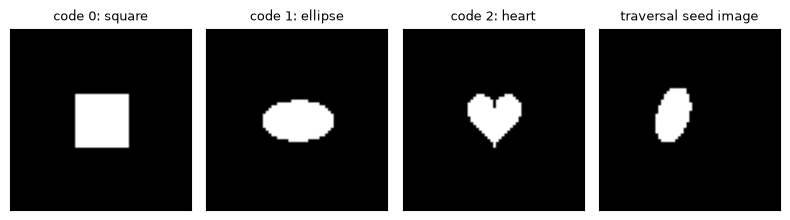

In [3]:
def factor_index_values(name):
    """Value of a factor for each class index, read from latents_values."""
    c = CLASSES[:, COL[name]]
    return np.bincount(c, weights=VALUES[:, COL[name]]) / np.bincount(c)

def first_index(**factor_idx):
    mask = np.ones(N_IMAGES, bool)
    for name, k in factor_idx.items():
        mask &= CLASSES[:, COL[name]] == min(int(k), SIZES[name] - 1)
    return int(np.flatnonzero(mask)[0])

def rotational_iou(img):
    """IoU of the (centroid-centred) object with itself rotated by 90 and by 180 degrees."""
    ys, xs = np.nonzero(img)
    shift = (int(round(31.5 - ys.mean())), int(round(31.5 - xs.mean())))
    c = np.roll(img, shift, axis=(0, 1))
    iou = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
    return float(iou(c, np.rot90(c, 1))), float(iou(c, np.rot90(c, 2)))

# Identify the shapes by symmetry: a square is unchanged by a 90-degree turn, an ellipse
# only by a 180-degree turn, a heart by neither. Largest scale, orientation 0, central position.
sym = {}
for s in range(SIZES["shape"]):
    i = first_index(shape=s, scale=SIZES["scale"] - 1, orientation=0,
                    posX=SIZES["posX"] // 2, posY=SIZES["posY"] // 2)
    sym[s] = (i, *rotational_iou(imgs_np[i].astype(bool)))
square = max(sym, key=lambda s: sym[s][1])
rest = [s for s in sym if s != square]
ellipse = max(rest, key=lambda s: sym[s][2])
heart = [s for s in rest if s != ellipse][0]
SHAPE_NAMES = [None] * SIZES["shape"]
SHAPE_NAMES[square], SHAPE_NAMES[ellipse], SHAPE_NAMES[heart] = "square", "ellipse", "heart"
documented = ["square", "ellipse", "heart"]   # dSprites documentation: shape values 1, 2, 3
for s, (i, r90, r180) in sym.items():
    print(f"shape code {s}: IoU(rot90)={r90:.2f} IoU(rot180)={r180:.2f} -> {SHAPE_NAMES[s]}")
print("matches the dataset documentation:", SHAPE_NAMES == documented)
r90 = sorted((v[1] for v in sym.values()), reverse=True)
if r90[0] - r90[1] < 0.1:
    print("WARNING: square vs. other shapes is not clearly separated by symmetry; check the images below")

# Which image axis does each position factor move the object along, and in which direction?
rng = np.random.default_rng(0)
sub = np.sort(rng.choice(N_IMAGES, size=min(20_000, N_IMAGES), replace=False))
im = imgs_np[sub].astype(np.float32)
mass = im.sum((1, 2))
row_c = (im.sum(2) * np.arange(64)).sum(1) / mass
col_c = (im.sum(1) * np.arange(64)).sum(1) / mass
LAYOUT = {}
for name in ("posX", "posY"):
    k = CLASSES[sub, COL[name]]
    cr, cc = np.corrcoef(k, row_c)[0, 1], np.corrcoef(k, col_c)[0, 1]
    axis = "row" if abs(cr) > abs(cc) else "col"
    LAYOUT[name] = dict(axis=axis, sign=int(np.sign(cr if axis == "row" else cc)),
                        corr_with_row=float(cr), corr_with_col=float(cc))
assert LAYOUT["posX"]["axis"] != LAYOUT["posY"]["axis"]
del im
print("position layout:", LAYOUT)

def to_image_layout(a):
    """a: array indexed [posX, posY, ...] -> [image row (top first), image column (left first), ...]."""
    if LAYOUT["posX"]["axis"] == "col":
        a = np.swapaxes(a, 0, 1)
        row_f, col_f = "posY", "posX"
    else:
        row_f, col_f = "posX", "posY"
    if LAYOUT[row_f]["sign"] < 0:
        a = a[::-1]
    if LAYOUT[col_f]["sign"] < 0:
        a = a[:, ::-1]
    return np.ascontiguousarray(a)

SCALE_VALUES = factor_index_values("scale")
ORIENT_VALUES = factor_index_values("orientation")
SEED_IMAGE_INDEX = first_index(shape=SHAPE_NAMES.index(TRAVERSAL_SEED_IMAGE["shape"]),
                               **{k: v for k, v in TRAVERSAL_SEED_IMAGE.items() if k != "shape"})
print(f"scale values: {np.round(SCALE_VALUES, 3)}")
print(f"orientation: {SIZES['orientation']} values from {ORIENT_VALUES[0]:.3f} to {ORIENT_VALUES[-1]:.3f} rad")
print("traversal seed image index:", SEED_IMAGE_INDEX, CLASSES[SEED_IMAGE_INDEX])

info = dict(path=str(DSPRITES_PATH), n_images=N_IMAGES, factor_names=FACTOR_NAMES, sizes=SIZES,
            shape_names=SHAPE_NAMES, shape_symmetry={str(s): v[1:] for s, v in sym.items()},
            layout=LAYOUT, scale_values=SCALE_VALUES.tolist(), orientation_values=ORIENT_VALUES.tolist(),
            seed_image_index=SEED_IMAGE_INDEX, seed_image_factors=TRAVERSAL_SEED_IMAGE)
(RUN_ROOT / "dataset_info.json").write_text(json.dumps(info, indent=2))

fig, axes = plt.subplots(1, 4, figsize=(8, 2.2))
for ax, s in zip(axes, range(SIZES["shape"])):
    ax.imshow(imgs_np[sym[s][0]], cmap="gray"); ax.set_title(f"code {s}: {SHAPE_NAMES[s]}", fontsize=9)
axes[3].imshow(imgs_np[SEED_IMAGE_INDEX], cmap="gray"); axes[3].set_title("traversal seed image", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [4]:
# Keep the whole dataset on the GPU as uint8 (~3.0 GB for the full set): no DataLoader, no host transfers.
IMGS_GPU = torch.from_numpy(imgs_np).to(DEVICE)
if DEVICE.type == "cuda":
    del imgs_np   # free ~3 GB of host RAM; everything below reads IMGS_GPU
    print(f"dataset on GPU: {IMGS_GPU.numel() / 2**30:.2f} GiB")

dataset on GPU: 2.81 GiB


## 6. Model, objective, training loop with checkpoints

The network follows Table 1 exactly; the encoder's 20-unit output head (μ, log σ²) is choice U5. The loss is the negative of Eq. 4 with the Bernoulli log-likelihood summed over the 4096 pixels and the analytic Gaussian KL summed over the 10 latents, averaged over the minibatch (U7).

Data order comes from a permutation seeded by (seed, epoch), so resuming needs only the step counter; the reparameterisation noise comes from its own seeded generator, whose state is saved in every checkpoint. Nothing else in training draws random numbers.

In [5]:
class FCVAE(nn.Module):
    """Table 1, 2D shapes (VAE)."""
    def __init__(self):
        super().__init__()
        layers, d = [], INPUT_DIM
        for h in ENC_HIDDEN:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.encoder = nn.Sequential(*layers)
        self.enc_out = nn.Linear(d, 2 * LATENT_DIM)       # U5: -> (mu, log sigma^2)
        layers, d = [], LATENT_DIM
        for h in DEC_HIDDEN:
            layers += [nn.Linear(d, h), nn.Tanh()]
            d = h
        layers.append(nn.Linear(d, INPUT_DIM))            # Bernoulli logits
        self.decoder = nn.Sequential(*layers)

    def encode(self, x):
        mu, logvar = self.enc_out(self.encoder(x)).chunk(2, dim=1)
        return mu, logvar

    def decode(self, z):
        return self.decoder(z)


def vae_terms(model, x, noise_gen):
    """Per-image -log p(x|z) (summed over pixels, Eq. 7) and per-latent KL(q(z|x) || N(0, I))."""
    mu, logvar = model.encode(x)
    eps = torch.randn(mu.shape, generator=noise_gen, device=mu.device, dtype=mu.dtype)
    z = mu + torch.exp(0.5 * logvar) * eps                 # U6: one sample per image
    logits = model.decode(z)
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)
    kl = 0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar)   # (B, M)
    return rec, kl


def train_step(model, opt, x, beta, noise_gen):
    rec, kl = vae_terms(model, x, noise_gen)
    loss = (rec + beta * kl.sum(1)).mean()                 # negative of Eq. 4, minibatch mean (U7)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    return rec.detach().mean(), loss.detach(), kl.detach().mean(0)


def make_optimizer(model):
    return torch.optim.Adagrad(model.parameters(), lr=LR)  # Table 1; other settings PyTorch defaults (U3)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)          # also seeds every CUDA device


def epoch_permutation(seed, epoch, n):
    g = torch.Generator().manual_seed(1_000_003 * seed + epoch)
    return torch.randperm(n, generator=g).to(DEVICE)


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def atomic_save(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def run_dir_for(beta, seed):
    return RUN_ROOT / f"beta{beta:g}_seed{seed}"

In [6]:
def train_run(beta, seed, plan):
    rd = run_dir_for(beta, seed)
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "DONE.json").exists():
        print(f"[skip] {rd.name}: finished"); return
    if (rd / "FAILED.json").exists():
        print(f"[skip] {rd.name}: marked FAILED ({json.loads((rd / 'FAILED.json').read_text())['reason']}); delete FAILED.json to retry"); return

    total_steps = int(plan["steps_per_run"])
    cfg = dict(beta=beta, seed=seed, total_steps=total_steps, batch_size=BATCH_SIZE, lr=LR,
               latent_dim=LATENT_DIM, enc_hidden=list(ENC_HIDDEN), dec_hidden=list(DEC_HIDDEN),
               optimizer="Adagrad (lr=1e-2; initial_accumulator_value=0, eps=1e-10, PyTorch defaults)",
               n_train=N_IMAGES, log_every=LOG_EVERY, ckpt_every=CKPT_EVERY,
               torch=torch.__version__, device=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu")
    cfg_path = rd / "config.json"
    if cfg_path.exists():
        old = json.loads(cfg_path.read_text())
        for k in ("beta", "seed", "total_steps", "batch_size", "lr", "latent_dim", "enc_hidden", "dec_hidden"):
            assert old[k] == cfg[k], f"{rd.name}: config mismatch on {k}: saved {old[k]} vs now {cfg[k]}"
    else:
        cfg_path.write_text(json.dumps(cfg, indent=2))

    seed_everything(seed)
    model = FCVAE().to(DEVICE)           # initialised on CPU from the seeded generator, then moved
    opt = make_optimizer(model)
    noise_gen = torch.Generator(device=DEVICE)
    noise_gen.manual_seed(10_000 + seed)
    step, seconds_before = 0, 0.0
    ckpt_path, log_path = rd / "ckpt.pt", rd / "train_log.jsonl"

    if ckpt_path.exists():
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        noise_gen.set_state(ck["noise_gen"])
        random.setstate(ck["py_rng"]); np.random.set_state(ck["np_rng"]); torch.set_rng_state(ck["torch_rng"])
        if DEVICE.type == "cuda" and ck.get("cuda_rng") is not None:
            torch.cuda.set_rng_state_all(ck["cuda_rng"])
        step, seconds_before = int(ck["step"]), float(ck["train_seconds"])
        print(f"[resume] {rd.name} from step {step:,}")
    # Drop log lines written after the checkpoint we resume from (they will be recomputed).
    if log_path.exists():
        keep = [l for l in log_path.read_text().splitlines() if l and json.loads(l)["step"] <= step]
        log_path.write_text("".join(l + "\n" for l in keep))
    elif step == 0:
        log_path.touch()

    n = IMGS_GPU.shape[0]
    spe = n // BATCH_SIZE                # steps per epoch (drop the last partial batch)
    perm, perm_epoch = None, -1
    acc = torch.zeros(2 + LATENT_DIM, device=DEVICE)
    acc_n = 0
    model.train()
    t0 = time.perf_counter()
    print(f"[train] {rd.name}: steps {step:,} -> {total_steps:,}  ({spe:,} steps/epoch)")
    with open(log_path, "a") as log_f:
        while step < total_steps:
            epoch, pos = divmod(step, spe)
            if epoch != perm_epoch:
                perm, perm_epoch = epoch_permutation(seed, epoch, n), epoch
            x = IMGS_GPU[perm[pos * BATCH_SIZE:(pos + 1) * BATCH_SIZE]].reshape(BATCH_SIZE, -1).float()
            r, l, k = train_step(model, opt, x, beta, noise_gen)
            acc[0] += r; acc[1] += l; acc[2:] += k
            acc_n += 1
            step += 1

            if step % LOG_EVERY == 0 or step == total_steps:
                v = (acc / acc_n).tolist()       # the only host sync in the loop
                secs = seconds_before + time.perf_counter() - t0
                if not all(math.isfinite(u) for u in v):
                    (rd / "FAILED.json").write_text(json.dumps(dict(step=step, reason="non-finite loss", train_seconds=secs)))
                    print(f"[FAILED] {rd.name}: non-finite loss at step {step:,}")
                    break
                log_f.write(json.dumps(dict(step=step, epoch=step / spe, rec=v[0], loss=v[1], kl_total=sum(v[2:]),
                                            kl_per_latent=v[2:], train_seconds=secs)) + "\n")
                log_f.flush()
                acc.zero_(); acc_n = 0
                if step % (LOG_EVERY * 20) == 0:
                    print(f"  step {step:>8,}  rec {v[0]:8.2f}  KL {sum(v[2:]):6.2f}  {secs / 60:5.1f} min")

            if step % CKPT_EVERY == 0 or step == total_steps:
                atomic_save(dict(model=model.state_dict(), opt=opt.state_dict(), step=step,
                                 noise_gen=noise_gen.get_state(), py_rng=random.getstate(),
                                 np_rng=np.random.get_state(), torch_rng=torch.get_rng_state(),
                                 cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None,
                                 train_seconds=seconds_before + time.perf_counter() - t0), ckpt_path)

    if not (rd / "FAILED.json").exists():
        secs = seconds_before + time.perf_counter() - t0
        atomic_save(dict(model=model.state_dict(), step=step, beta=beta, seed=seed), rd / "final.pt")
        last = json.loads(log_path.read_text().splitlines()[-1])
        (rd / "DONE.json").write_text(json.dumps(dict(steps=step, train_seconds=secs, final_rec=last["rec"],
                                                      final_kl=last["kl_total"]), indent=2))
        ckpt_path.unlink(missing_ok=True)
        print(f"[done] {rd.name}: {step:,} steps in {secs / 60:.1f} min (this run, incl. earlier sessions)")
    del model, opt
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

## 7. Compute plan: benchmark once, then fix the number of seeds and steps

This times the exact training step on your GPU (with the real data), applies the rule from §3, and writes `plan.json`. If `plan.json` already exists it is loaded as is, so a resumed session never changes the run length.

In [7]:
PLAN_PATH = RUN_ROOT / "plan.json"

def benchmark_seconds_per_step():
    seed_everything(12_345)
    model = FCVAE().to(DEVICE)
    opt = make_optimizer(model)
    gen = torch.Generator(device=DEVICE); gen.manual_seed(0)
    idx = torch.randint(0, IMGS_GPU.shape[0], (BENCH_WARMUP + BENCH_STEPS, BATCH_SIZE),
                        generator=torch.Generator().manual_seed(0)).to(DEVICE)
    acc = torch.zeros(2 + LATENT_DIM, device=DEVICE)
    def one(i):
        x = IMGS_GPU[idx[i]].reshape(BATCH_SIZE, -1).float()
        r, l, k = train_step(model, opt, x, 4.0, gen)
        acc[0] += r; acc[1] += l; acc[2:] += k
    for i in range(BENCH_WARMUP):
        one(i)
    sync(); t = time.perf_counter()
    for i in range(BENCH_STEPS):
        one(BENCH_WARMUP + i)
    sync()
    sps = (time.perf_counter() - t) / BENCH_STEPS
    del model, opt
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return sps

if PLAN_PATH.exists():
    PLAN = json.loads(PLAN_PATH.read_text())
    print("loaded existing plan (not re-benchmarking, so resumed runs keep the same length)")
else:
    t_bench = time.perf_counter()
    sps = benchmark_seconds_per_step()
    budget_s = TRAIN_BUDGET_MIN * 60
    fit = lambda n_runs: int(budget_s / (n_runs * sps * SAFETY))
    n_b = len(BETAS)
    s3 = fit(3 * n_b)
    if s3 >= DEFAULT_STEPS:
        n_seeds, steps, why = 3, DEFAULT_STEPS, "3 seeds at the default length fit"
    elif s3 >= MIN_STEPS_FOR_3_SEEDS:
        n_seeds, steps, why = 3, s3, "3 seeds fit only at a shorter length (still >= minimum)"
    elif fit(2 * n_b) >= MIN_STEPS_FOR_3_SEEDS:
        n_seeds, steps, why = 2, min(DEFAULT_STEPS, fit(2 * n_b)), "3 seeds would force runs below the minimum length; length beats a 3rd seed"
    else:
        n_seeds, steps, why = 1, min(DEFAULT_STEPS, fit(n_b)), "even 2 seeds fall below the minimum length; single-seed anecdote only"
    steps = max(LOG_EVERY, (steps // LOG_EVERY) * LOG_EVERY)
    seeds = list(SEEDS_WANTED[:n_seeds])
    run_order = [[b, s] for s in seeds for b in BETAS]       # seed 0 of every beta first
    PLAN = dict(seconds_per_step=sps, safety=SAFETY, train_budget_min=TRAIN_BUDGET_MIN,
                n_seeds=n_seeds, seeds=seeds, steps_per_run=steps, epochs_per_run=steps * BATCH_SIZE / N_IMAGES,
                projected_train_min=len(run_order) * steps * sps / 60, reason=why, run_order=run_order,
                benchmark_seconds=time.perf_counter() - t_bench)
    PLAN_PATH.write_text(json.dumps(PLAN, indent=2))

print(json.dumps(PLAN, indent=2))
RUN_ORDER = [tuple(r) for r in PLAN["run_order"]]

{
  "seconds_per_step": 0.0024873883998952806,
  "safety": 1.1,
  "train_budget_min": 110.0,
  "n_seeds": 3,
  "seeds": [
    0,
    1,
    2
  ],
  "steps_per_run": 300000,
  "epochs_per_run": 26.041666666666668,
  "projected_train_min": 74.62165199685842,
  "reason": "3 seeds at the default length fit",
  "run_order": [
    [
      4.0,
      0
    ],
    [
      1.0,
      0
    ],
    [
      4.0,
      1
    ],
    [
      1.0,
      1
    ],
    [
      4.0,
      2
    ],
    [
      1.0,
      2
    ]
  ],
  "benchmark_seconds": 3.3716653999872506
}


## 8. Phase 1 — seed 0 of each β (gives a usable figure early)

In [8]:
PHASE1 = RUN_ORDER[:len(BETAS)]
for beta, seed in PHASE1:
    train_run(beta, seed, PLAN)

[train] beta4_seed0: steps 0 -> 300,000  (11,520 steps/epoch)
  step   20,000  rec    96.23  KL   9.70    0.8 min
  step   40,000  rec    94.21  KL   9.73    1.7 min
  step   60,000  rec    86.91  KL  10.32    2.5 min
  step   80,000  rec    79.91  KL  10.76    3.4 min
  step  100,000  rec    77.50  KL  10.89    4.2 min
  step  120,000  rec    75.36  KL  11.00    5.1 min
  step  140,000  rec    73.40  KL  11.11    5.9 min
  step  160,000  rec    71.61  KL  11.21    6.8 min
  step  180,000  rec    69.72  KL  11.32    7.6 min
  step  200,000  rec    67.97  KL  11.43    8.5 min
  step  220,000  rec    66.38  KL  11.52    9.3 min
  step  240,000  rec    65.34  KL  11.59   10.2 min
  step  260,000  rec    64.28  KL  11.66   11.1 min
  step  280,000  rec    63.44  KL  11.71   11.9 min
  step  300,000  rec    62.26  KL  11.78   12.8 min
[done] beta4_seed0: 300,000 steps in 12.8 min (this run, incl. earlier sessions)
[train] beta1_seed0: steps 0 -> 300,000  (11,520 steps/epoch)
  step   20,000

## 9. Analysis: compute every plotted quantity from the final checkpoint and save it

For each finished run this encodes all 737,280 images, then writes `analysis.npz` containing the learnt variances and per-latent KL, the column order, the three mean-response rows (posterior means μ, grouped by factor), the traversal images, and the ANOVA variance shares used for the annotation (U20). The plotting code in §10 reads only these files and the training logs.

In [9]:
FACTOR_KEYS = ("shape", "scale", "rotation", "posX", "posY")

@torch.no_grad()
def encode_all(model, chunk=16_384):
    mus, logvars = [], []
    for i in range(0, IMGS_GPU.shape[0], chunk):
        mu, lv = model.encode(IMGS_GPU[i:i + chunk].reshape(-1, INPUT_DIM).float())
        mus.append(mu.cpu()); logvars.append(lv.cpu())
    return torch.cat(mus).double().numpy(), torch.cat(logvars).double().numpy()

def group_mean(vals, names):
    """Mean of vals (N, M) for every combination of the named factors -> (*sizes, M), plus counts."""
    sizes = tuple(SIZES[n] for n in names)
    flat = np.ravel_multi_index(CLASSES[:, [COL[n] for n in names]].T, sizes)
    G = int(np.prod(sizes))
    cnt = np.bincount(flat, minlength=G)
    sums = np.stack([np.bincount(flat, weights=vals[:, m], minlength=G) for m in range(vals.shape[1])], -1)
    return (sums / cnt[:, None]).reshape(*sizes, vals.shape[1]), cnt.reshape(sizes)

def between_var(mu, names):
    gm, cnt = group_mean(mu, names)
    gm = gm.reshape(-1, mu.shape[1]); w = cnt.reshape(-1) / cnt.sum()
    return (w[:, None] * (gm - mu.mean(0)) ** 2).sum(0)

def factor_variance_fractions(mu):
    """Share of Var(mu_m) explained by each factor (balanced design, so the main effects are additive).
    'rotation' = shape x orientation cells minus the shape main effect, i.e. rotation including its
    shape-dependent part (the symmetry period differs per shape)."""
    tot = np.maximum(mu.var(0), 1e-12)
    parts = dict(shape=between_var(mu, ["shape"]), scale=between_var(mu, ["scale"]),
                 posX=between_var(mu, ["posX"]), posY=between_var(mu, ["posY"]))
    parts["rotation"] = between_var(mu, ["shape", "orientation"]) - parts["shape"]
    return np.stack([parts[k] / tot for k in FACTOR_KEYS], 1)      # (M, 5)

@torch.no_grad()
def traversal_images(model, img_index, values):
    x0 = IMGS_GPU[img_index].reshape(1, -1).float()
    mu0, _ = model.encode(x0)                                     # U15: others fixed at the posterior mean
    M, T = mu0.shape[1], len(values)
    z = mu0.repeat(M * T, 1).reshape(M, T, M).clone()
    v = torch.as_tensor(values, dtype=z.dtype, device=z.device)
    for m in range(M):
        z[m, :, m] = v                                            # latent m replaced by -3..3
    imgs = torch.sigmoid(model.decode(z.reshape(M * T, M))).reshape(M, T, 64, 64)   # U16: Bernoulli means
    recon = torch.sigmoid(model.decode(mu0)).reshape(64, 64)
    return imgs.cpu().float().numpy(), recon.cpu().float().numpy(), mu0[0].cpu().double().numpy()

def analyze_run(beta, seed, force=False):
    rd = run_dir_for(beta, seed); out = rd / "analysis.npz"
    if not (rd / "DONE.json").exists():
        print(f"[analysis] {rd.name}: not finished, skipped"); return None
    if out.exists() and not force and out.stat().st_mtime >= (rd / "final.pt").stat().st_mtime:
        return out
    t0 = time.perf_counter()
    model = FCVAE().to(DEVICE)
    model.load_state_dict(torch.load(rd / "final.pt", map_location=DEVICE, weights_only=False)["model"])
    model.eval()
    mu, logvar = encode_all(model)
    var = np.exp(logvar)
    learnt_variance = var.mean(0)                                           # U10
    kl_per_latent = (0.5 * (mu ** 2 + var - 1.0 - logvar)).mean(0)
    order = np.argsort(learnt_variance, kind="stable")                      # Fig. 7: ascending learnt variance
    pos, _ = group_mean(mu, ["posX", "posY"])                               # row 1
    sc, _ = group_mean(mu, ["shape", "scale"])                              # row 2
    rot, _ = group_mean(mu, ["shape", "orientation"])                       # row 3
    trav, recon, mu0 = traversal_images(model, SEED_IMAGE_INDEX, TRAVERSAL_VALUES)   # rows 4-8
    np.savez_compressed(
        out, beta=beta, seed=seed,
        learnt_variance=learnt_variance, kl_per_latent=kl_per_latent, order=order, mu_std=mu.std(0),
        position_map=np.moveaxis(to_image_layout(pos), -1, 0),              # (M, rows, cols), image orientation
        scale_curve=np.moveaxis(sc, -1, 0), rot_curve=np.moveaxis(rot, -1, 0),
        scale_values=SCALE_VALUES, orientation_values=ORIENT_VALUES, shape_names=np.array(SHAPE_NAMES),
        factor_keys=np.array(FACTOR_KEYS), factor_fractions=factor_variance_fractions(mu),
        traversal=trav, traversal_values=TRAVERSAL_VALUES, seed_index=SEED_IMAGE_INDEX,
        seed_image=IMGS_GPU[SEED_IMAGE_INDEX].cpu().numpy(), seed_recon=recon, seed_mu=mu0,
        analysis_seconds=time.perf_counter() - t0)
    del model
    print(f"[analysis] {rd.name}: saved {out} ({time.perf_counter() - t0:.1f}s)")
    return out

def load_analysis(beta, seed):
    p = run_dir_for(beta, seed) / "analysis.npz"
    return dict(np.load(p)) if p.exists() else None

## 10. Plotting (reads only `analysis.npz` and `train_log.jsonl`)

In [10]:
def paper_columns(A, n_informative=5):
    """U12: the 5 lowest-variance latents plus the single highest-variance one."""
    order = [int(i) for i in A["order"]]
    return order if len(order) <= n_informative + 1 else order[:n_informative] + [order[-1]]

def column_note(A, m):
    if A["kl_per_latent"][m] < KL_INACTIVE_NATS:
        tag = "inactive"
    else:
        j = int(np.argmax(A["factor_fractions"][m]))
        tag = f"{A['factor_keys'][j]} {A['factor_fractions'][m, j]:.2f}"
    return f"{A['learnt_variance'][m]:.2f}\n{tag}"

def draw_panel(subfig, A, cols, title):
    T = len(A["traversal_values"]); n = len(cols)
    gs = subfig.add_gridspec(3 + T, n, height_ratios=[1.0, 0.7, 0.7] + [1.0] * T,
                             hspace=0.08, wspace=0.08, left=0.13, right=0.98, top=0.88, bottom=0.13)
    a = float(np.abs(A["position_map"][cols]).max()) or 1.0              # U17: shared symmetric range
    ys = 1.1 * float(np.abs(A["scale_curve"][cols]).max()) or 1.0
    yr = 1.1 * float(np.abs(A["rot_curve"][cols]).max()) or 1.0
    names = [str(s) for s in A["shape_names"]]
    highest = int(A["order"][-1])
    for j, m in enumerate(cols):
        ax = subfig.add_subplot(gs[0, j])
        ax.imshow(A["position_map"][m], cmap="jet", vmin=-a, vmax=a, interpolation="nearest")
        ttl = f"$z_{{{m + 1}}}$" + ("\n(max $\\sigma^2$)" if (m == highest and n < len(A["order"])) else "")
        ax.set_title(ttl, fontsize=10)
        if j == 0: ax.set_ylabel(f"position\n(±{a:.2f})", fontsize=8)
        ax = subfig.add_subplot(gs[1, j])
        for s, nm in enumerate(names):
            ax.plot(A["scale_values"], A["scale_curve"][m, s], color=SHAPE_COLORS[nm], lw=1)
        ax.set_ylim(-ys, ys)
        if j == 0: ax.set_ylabel(f"scale\n(±{ys:.2f})", fontsize=8)
        ax = subfig.add_subplot(gs[2, j])
        for s, nm in enumerate(names):
            ax.plot(A["orientation_values"], A["rot_curve"][m, s], color=SHAPE_COLORS[nm], lw=1)
        ax.set_ylim(-yr, yr)
        if j == 0: ax.set_ylabel(f"rotation\n(±{yr:.2f})", fontsize=8)
        for t in range(T):
            ax = subfig.add_subplot(gs[3 + t, j])
            ax.imshow(A["traversal"][m, t], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
            v = float(A["traversal_values"][t])
            if j == 0: ax.set_ylabel("0" if v == 0 else f"{v:+g}", fontsize=8, rotation=0, labelpad=12, va="center")
            if t == T - 1: ax.set_xlabel(column_note(A, m), fontsize=8)
    for ax in subfig.axes:
        ax.set_xticks([]); ax.set_yticks([])
    subfig.text(0.005, 0.075, "learnt σ²\n& top factor", fontsize=8, va="center")
    subfig.suptitle(title, fontsize=12, x=0.13, ha="left")

def shape_legend(fig):
    handles = [Line2D([0], [0], color=c, lw=2, label=k) for k, c in SHAPE_COLORS.items()]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=9, frameon=False)

def plot_fig7(seed, full=False):
    As = {b: load_analysis(b, seed) for b in BETAS}
    missing = [b for b, A in As.items() if A is None]
    if missing:
        print(f"seed {seed}: no analysis for beta {missing} (not finished or FAILED)"); return
    if full:
        for b, A in As.items():
            fig = plt.figure(figsize=(13, 9.5))
            draw_panel(fig, A, [int(i) for i in A["order"]], f"β = {b:g}, seed {seed}: all {len(A['order'])} latents, ordered by learnt variance")
            shape_legend(fig)
            fig.savefig(FIG_DIR / f"fig7_full_beta{b:g}_seed{seed}.png", dpi=130); plt.show()
        return
    fig = plt.figure(figsize=(16, 9.5))
    sA, sB = fig.subfigures(1, 2, wspace=0.03)
    draw_panel(sA, As[4.0], paper_columns(As[4.0]), f"A   β-VAE (β = 4), seed {seed}")
    draw_panel(sB, As[1.0], paper_columns(As[1.0]), f"B   VAE (β = 1), seed {seed}")
    shape_legend(fig)
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig7AB_seed{seed}.{ext}", dpi=150)
    plt.show()
    print("Under each column: learnt variance, then the factor explaining the largest share of the latent's "
          "mean-response variance (U20). Traversal seed image index:", int(As[4.0]["seed_index"]))

def read_log(beta, seed):
    p = run_dir_for(beta, seed) / "train_log.jsonl"
    if not p.exists(): return None
    rows = [json.loads(l) for l in p.read_text().splitlines() if l]
    return {k: np.array([r[k] for r in rows]) for k in rows[0]} if rows else None

## 11. Figure 7A/B from seed 0

[analysis] beta4_seed0: saved runs_fig7\beta4_seed0\analysis.npz (1.7s)
[analysis] beta1_seed0: saved runs_fig7\beta1_seed0\analysis.npz (1.7s)


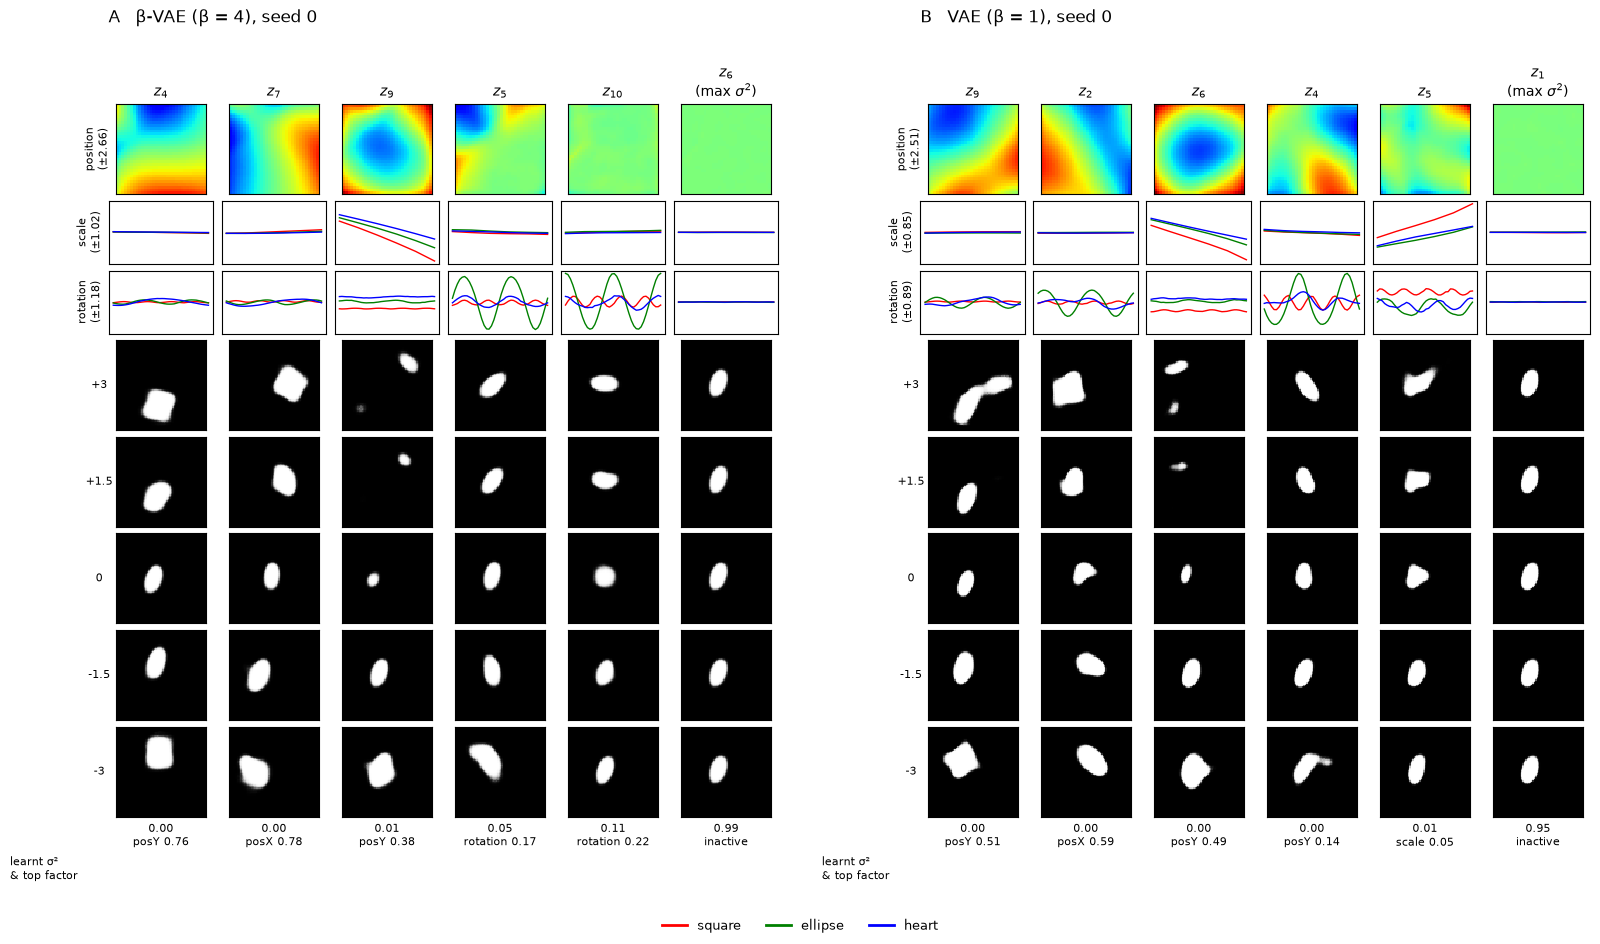

Under each column: learnt variance, then the factor explaining the largest share of the latent's mean-response variance (U20). Traversal seed image index: 377166


In [11]:
for beta, seed in PHASE1:
    analyze_run(beta, seed)
plot_fig7(MAIN_FIGURE_SEED)

## 12. Phase 2 — remaining seeds

In [12]:
for beta, seed in RUN_ORDER[len(BETAS):]:
    train_run(beta, seed, PLAN)
for beta, seed in RUN_ORDER:
    analyze_run(beta, seed)

[train] beta4_seed1: steps 0 -> 300,000  (11,520 steps/epoch)
  step   20,000  rec    95.67  KL   9.64    0.8 min
  step   40,000  rec    93.90  KL   9.70    1.7 min
  step   60,000  rec    92.58  KL   9.72    2.6 min
  step   80,000  rec    84.63  KL  10.45    3.4 min
  step  100,000  rec    78.69  KL  10.78    4.3 min
  step  120,000  rec    76.24  KL  10.91    5.1 min
  step  140,000  rec    74.60  KL  11.01    6.0 min
  step  160,000  rec    72.90  KL  11.08    6.8 min
  step  180,000  rec    71.21  KL  11.18    7.7 min
  step  200,000  rec    69.52  KL  11.30    8.5 min
  step  220,000  rec    67.88  KL  11.38    9.3 min
  step  240,000  rec    66.58  KL  11.48   10.2 min
  step  260,000  rec    65.33  KL  11.56   11.1 min
  step  280,000  rec    63.88  KL  11.62   11.9 min
  step  300,000  rec    63.30  KL  11.68   12.8 min
[done] beta4_seed1: 300,000 steps in 12.8 min (this run, incl. earlier sessions)
[train] beta1_seed1: steps 0 -> 300,000  (11,520 steps/epoch)
  step   20,000

## 13. Results across seeds

First the main figure again (seed 0, fixed in advance), then the same figure for every other seed, the full 10-latent panels, the training curves, and per-seed tables. Any run marked FAILED is listed rather than replaced.

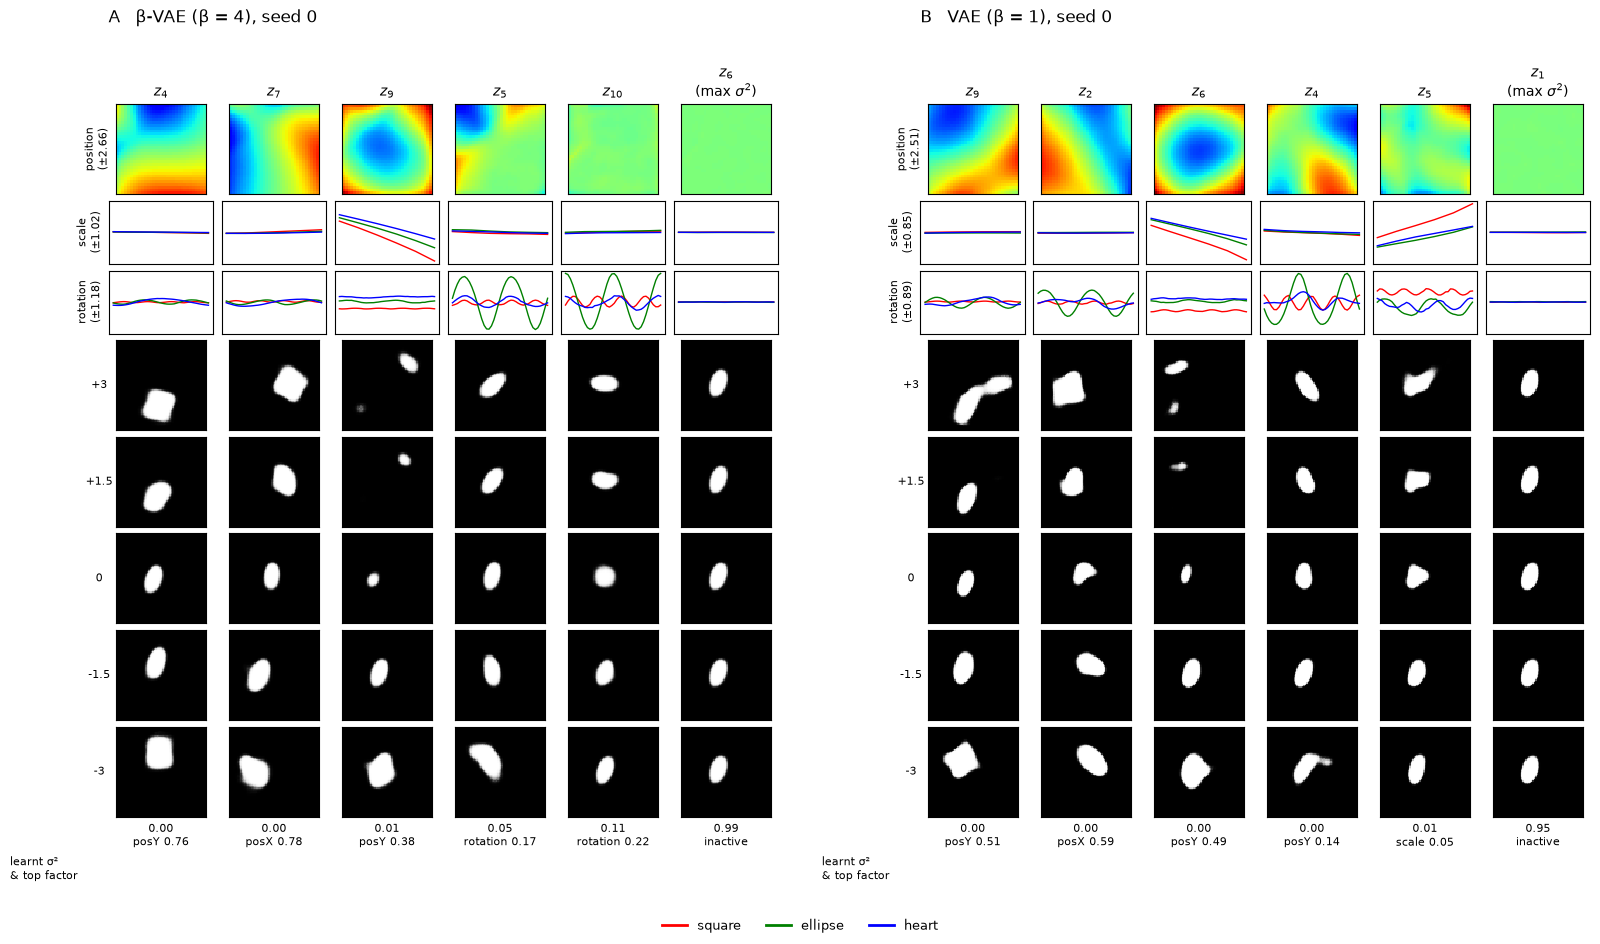

Under each column: learnt variance, then the factor explaining the largest share of the latent's mean-response variance (U20). Traversal seed image index: 377166


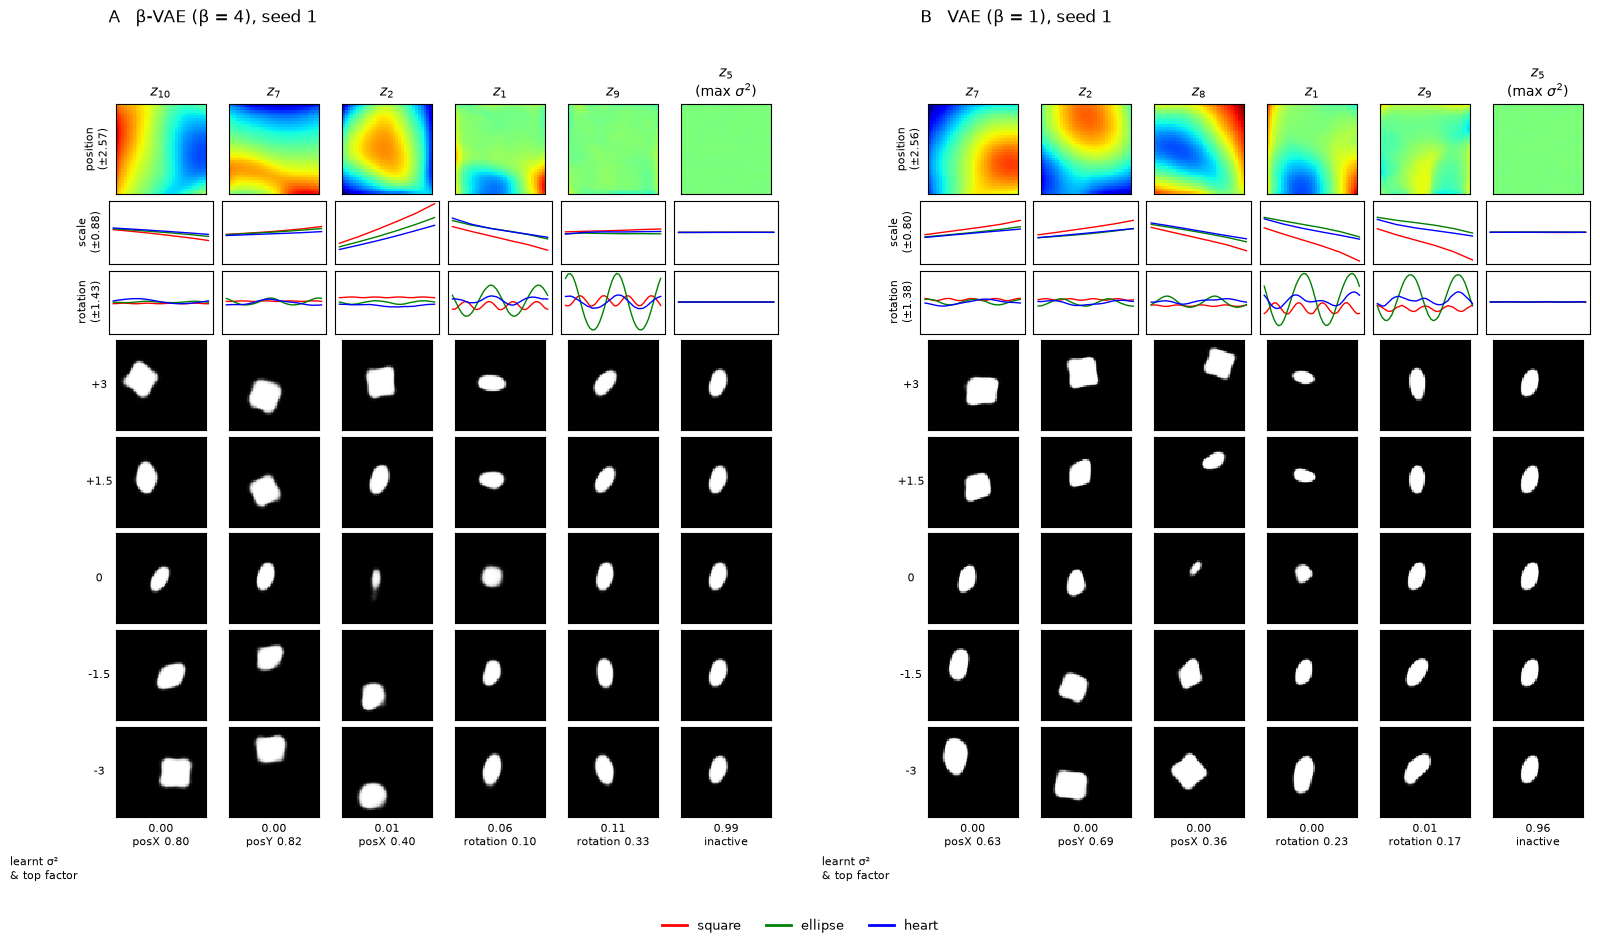

Under each column: learnt variance, then the factor explaining the largest share of the latent's mean-response variance (U20). Traversal seed image index: 377166


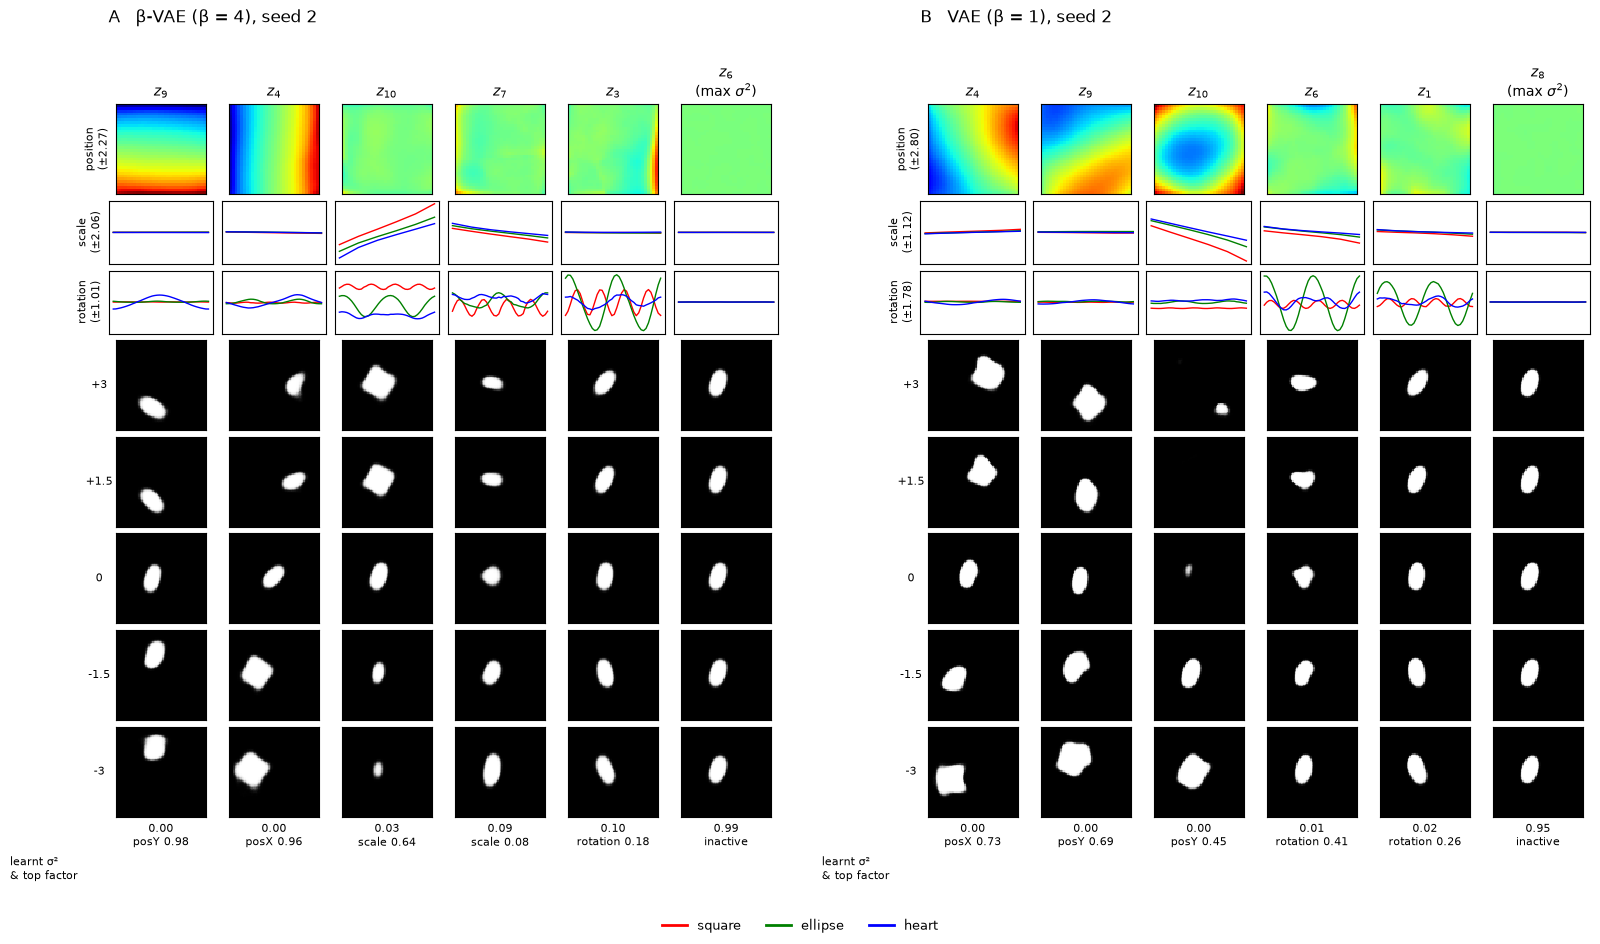

Under each column: learnt variance, then the factor explaining the largest share of the latent's mean-response variance (U20). Traversal seed image index: 377166


In [13]:
plot_fig7(MAIN_FIGURE_SEED)
for s in PLAN["seeds"]:
    if s != MAIN_FIGURE_SEED:
        plot_fig7(s)

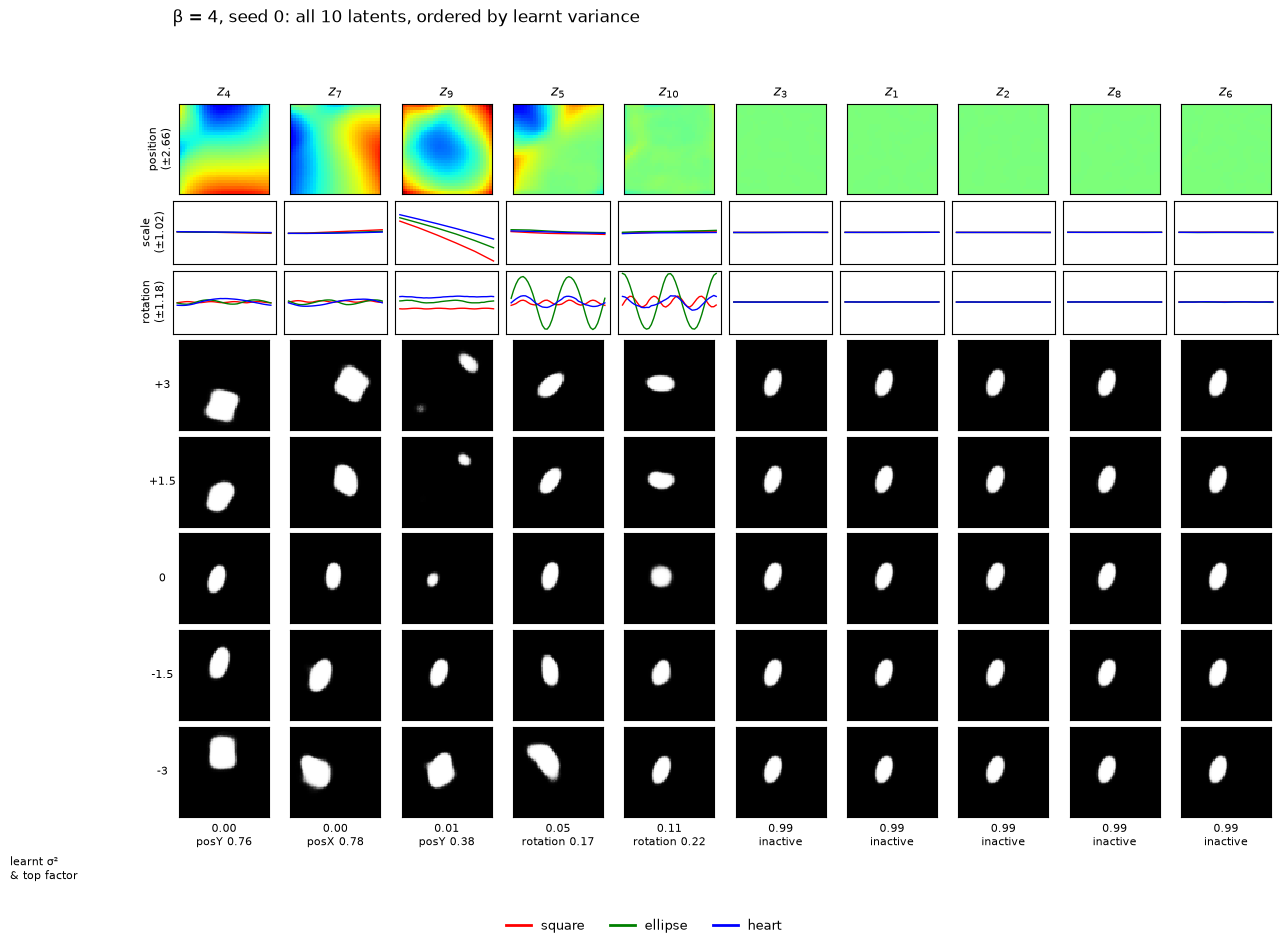

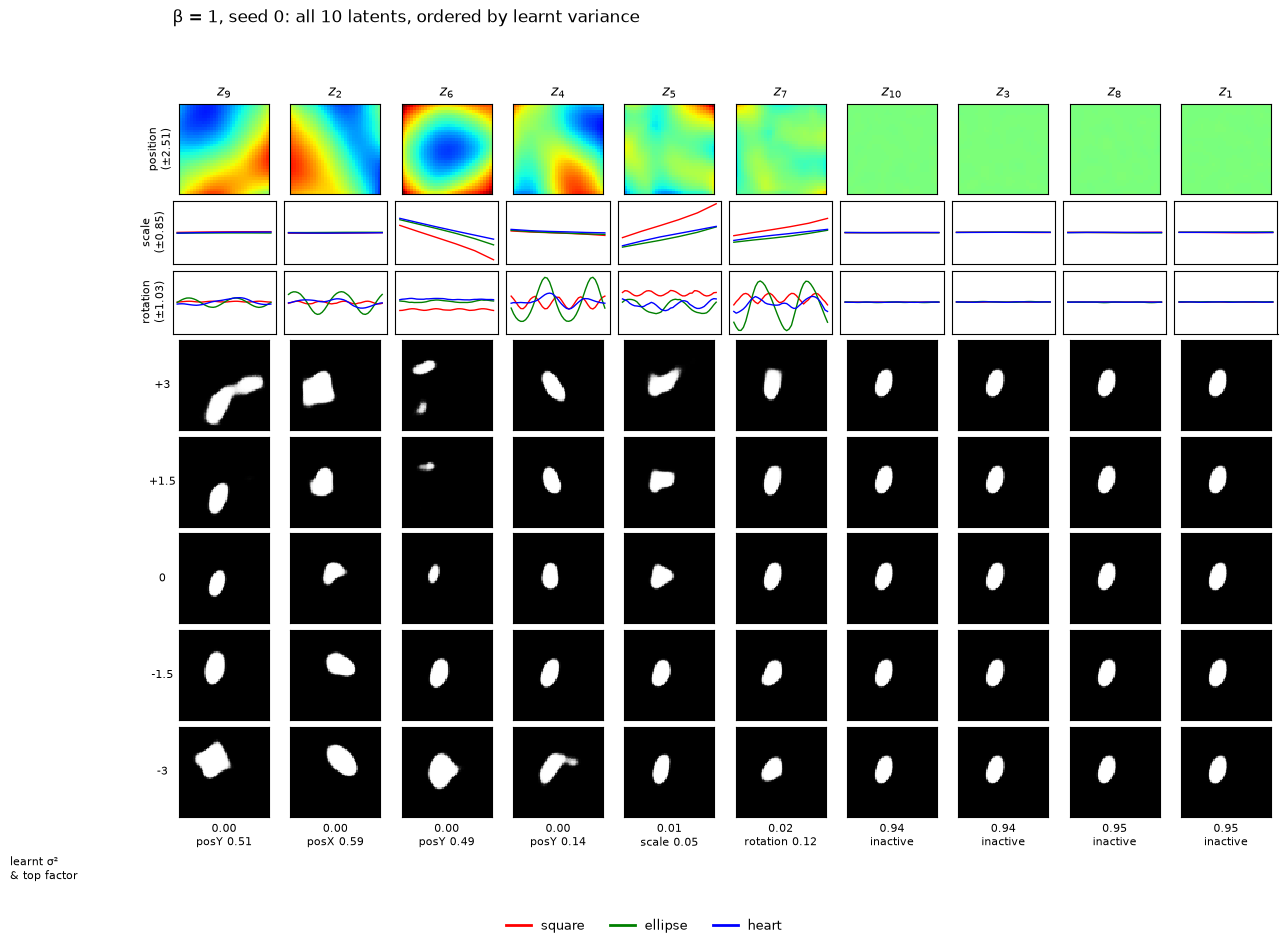

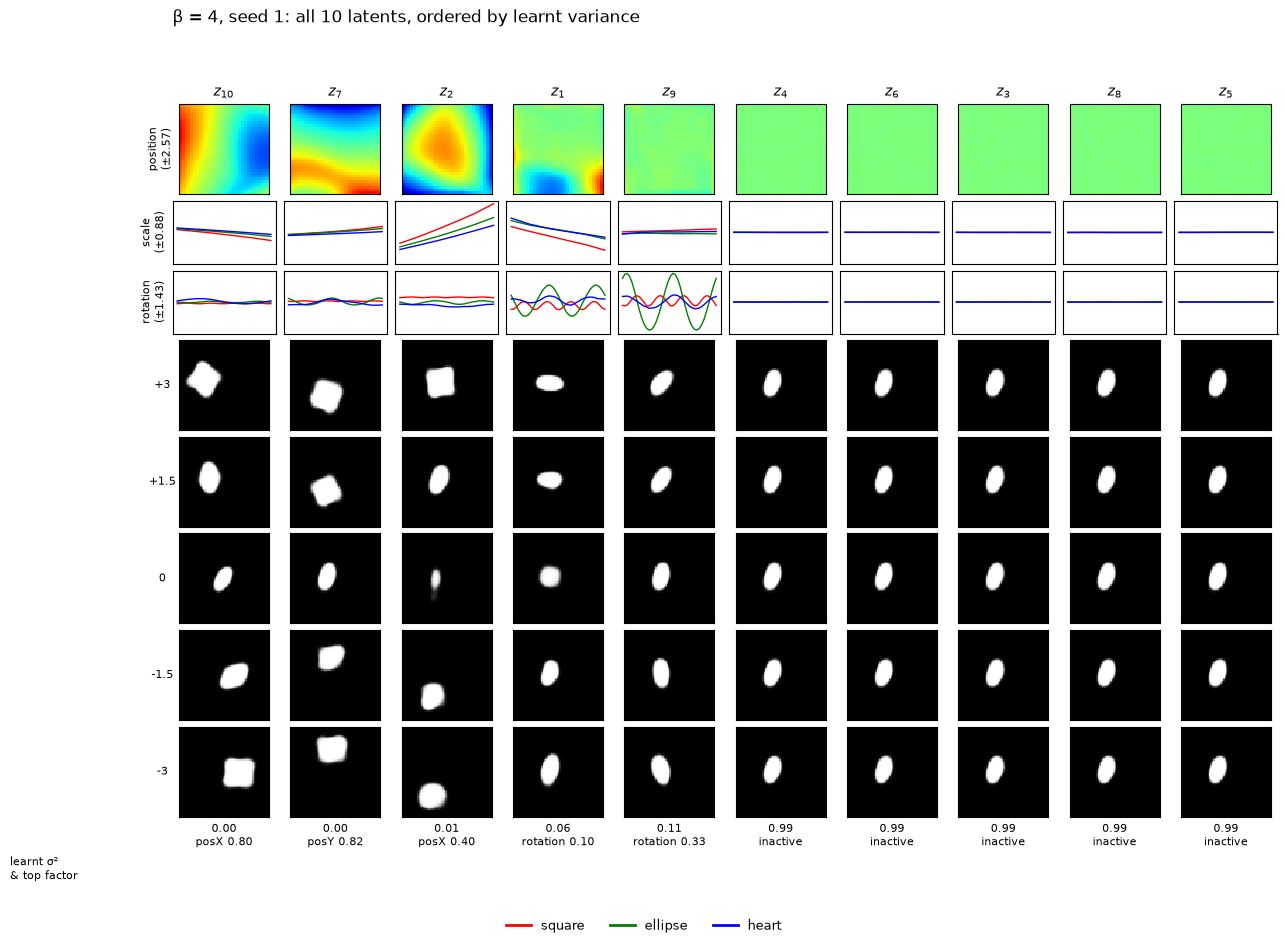

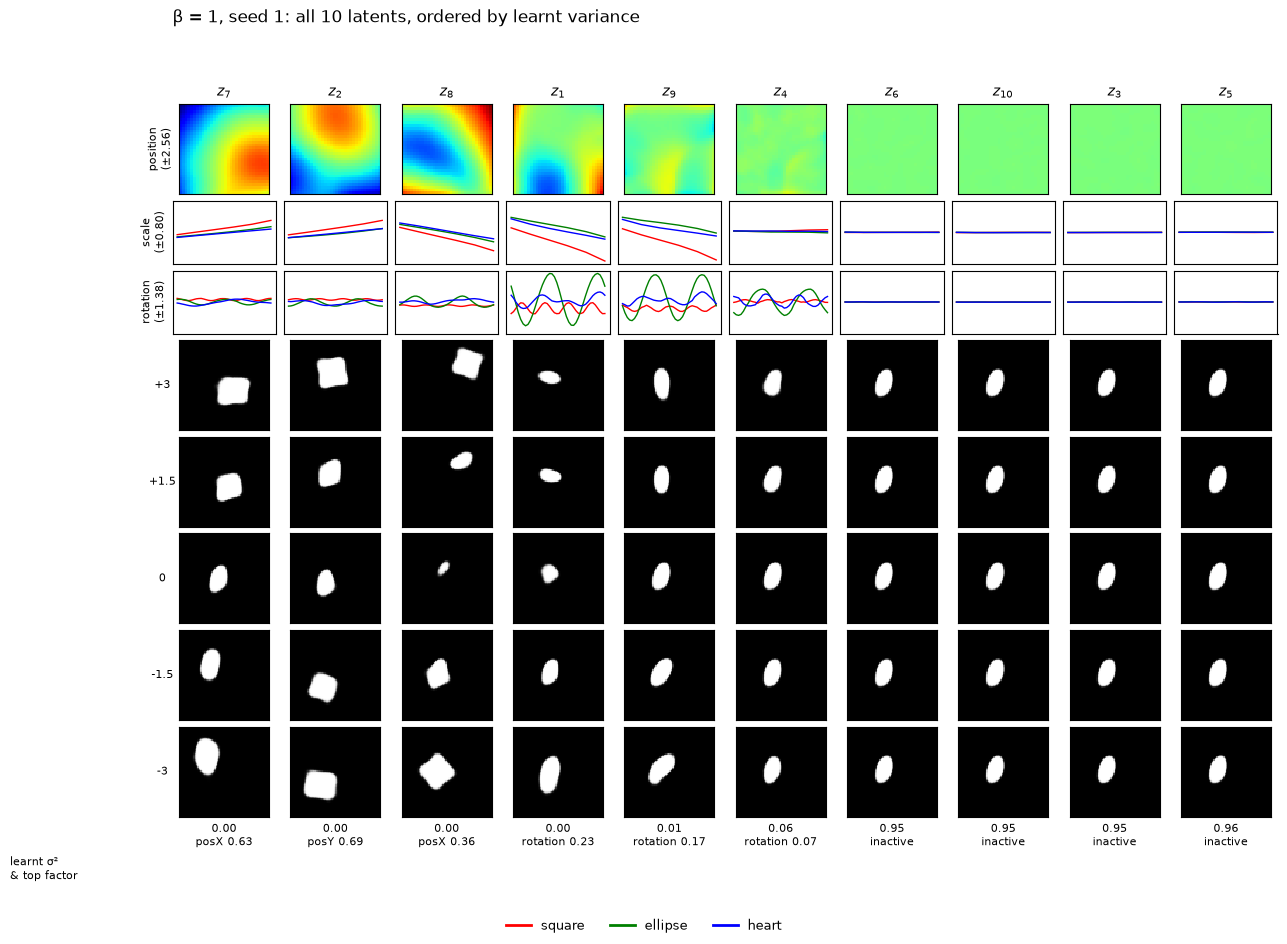

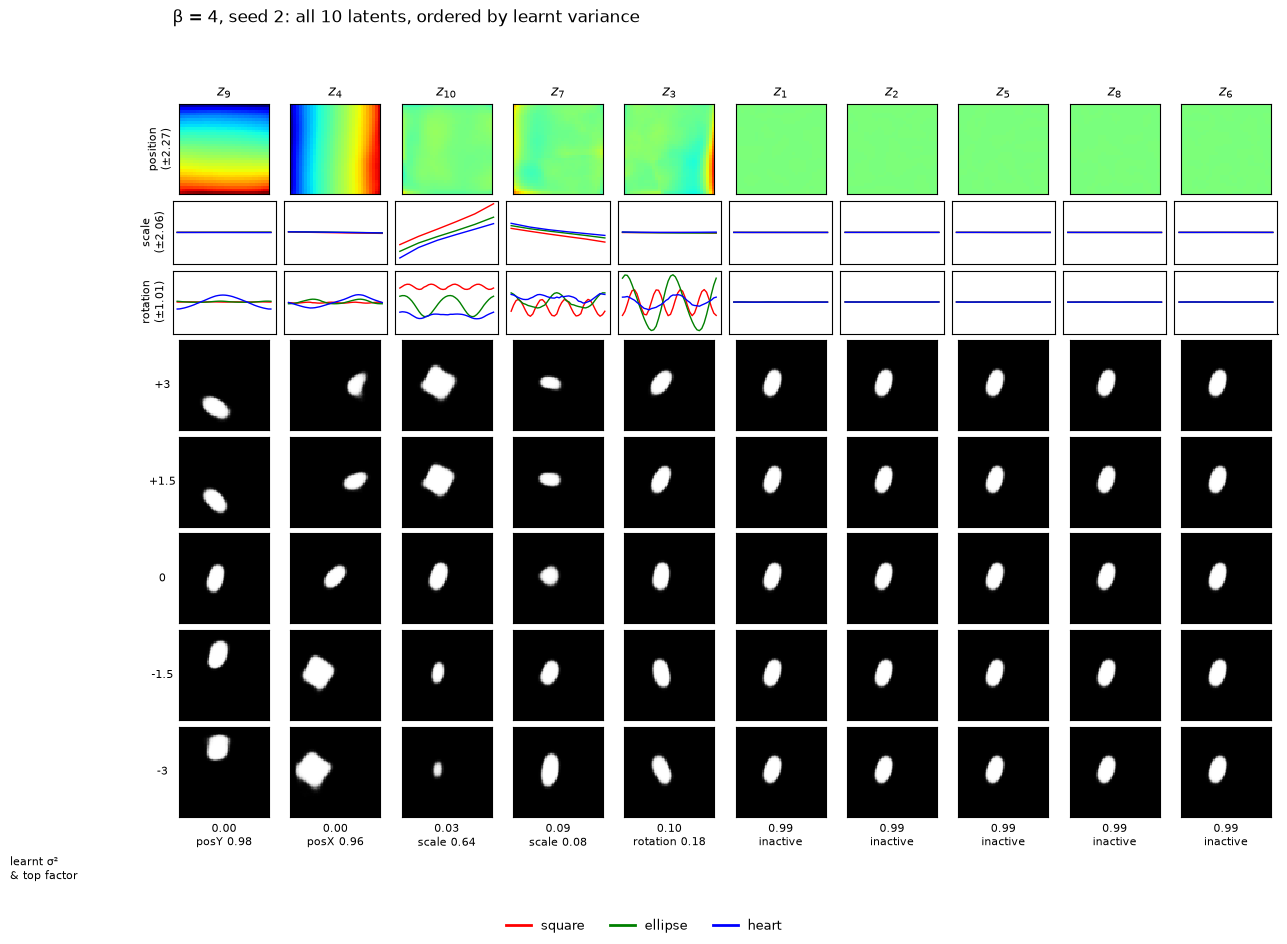

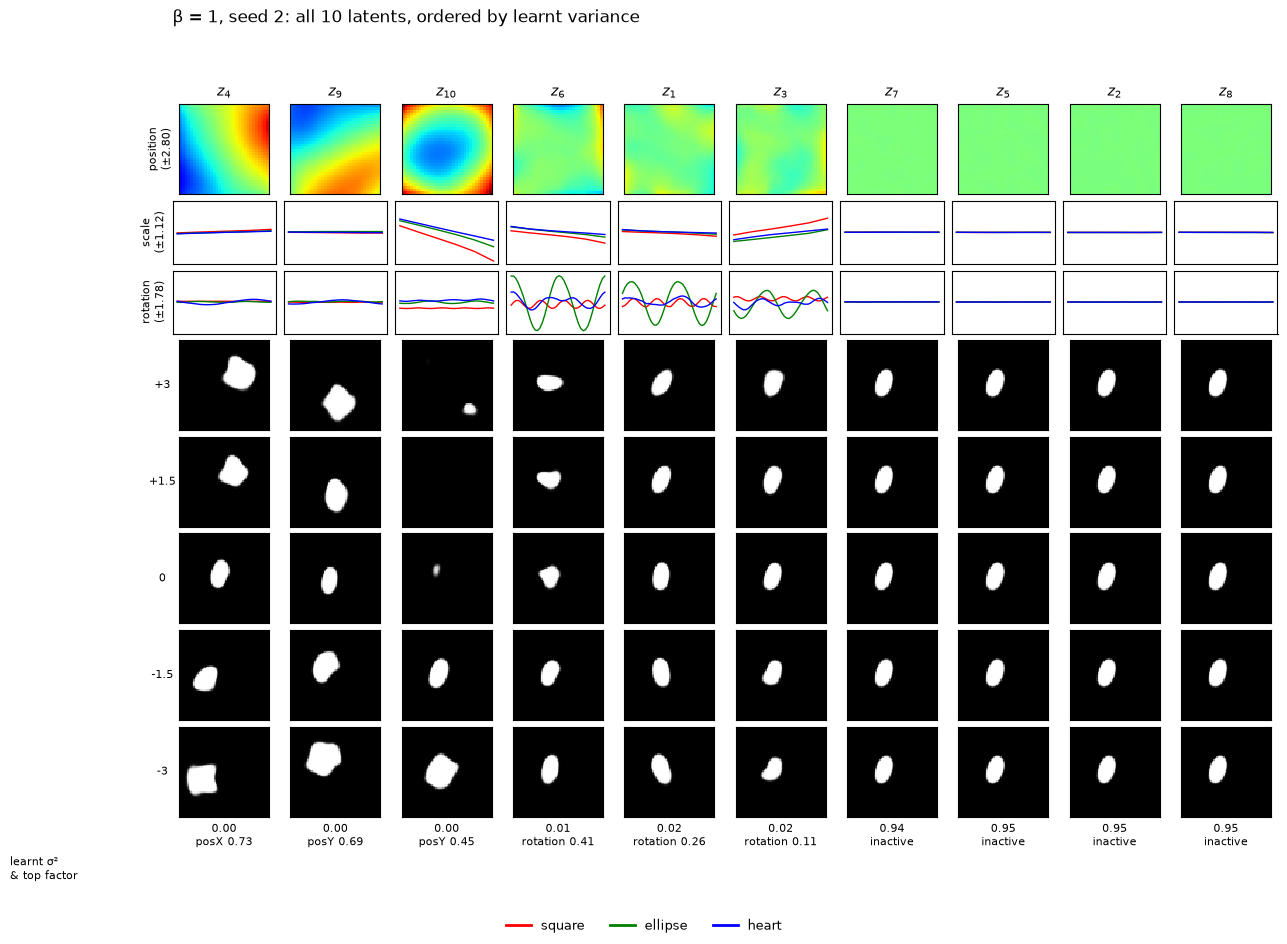

In [14]:
for s in PLAN["seeds"]:
    plot_fig7(s, full=True)

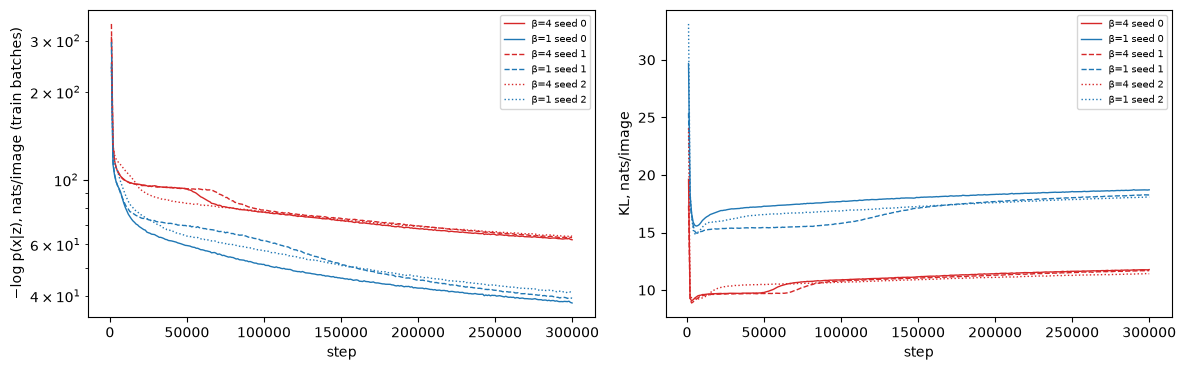

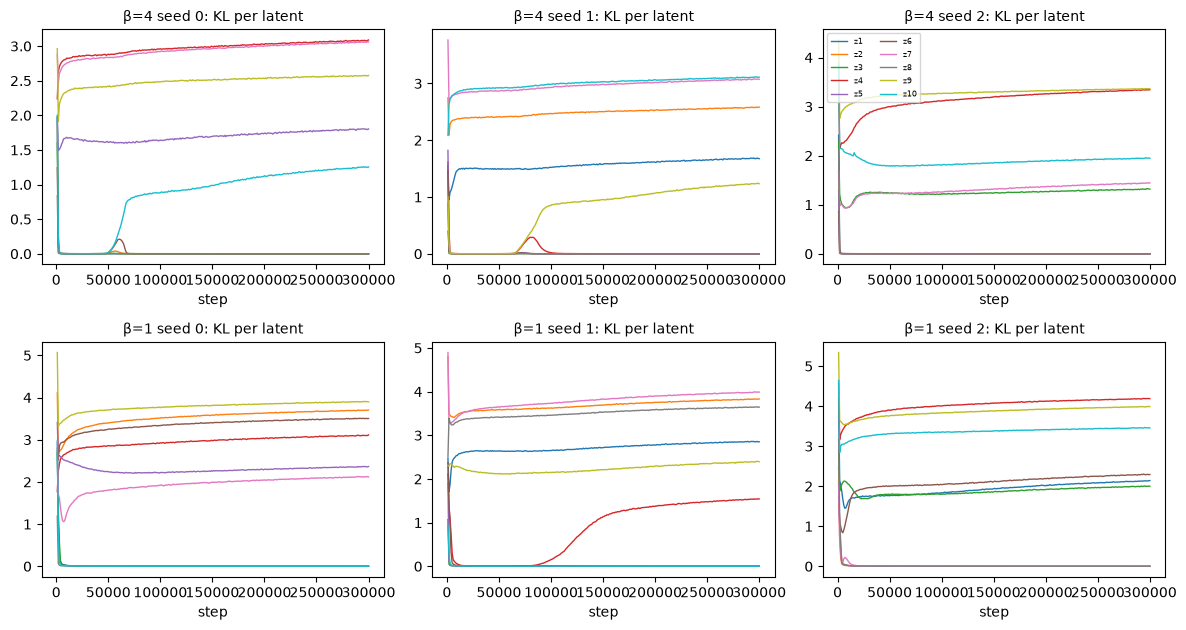

In [15]:
# Training curves and per-latent KL over training, from train_log.jsonl
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for beta, seed in RUN_ORDER:
    L = read_log(beta, seed)
    if L is None: continue
    kw = dict(color="tab:red" if beta == 4.0 else "tab:blue", ls=["-", "--", ":"][seed % 3], lw=1,
              label=f"β={beta:g} seed {seed}")
    axes[0].plot(L["step"], L["rec"], **kw); axes[1].plot(L["step"], L["kl_total"], **kw)
axes[0].set_ylabel("−log p(x|z), nats/image (train batches)"); axes[1].set_ylabel("KL, nats/image")
for ax in axes: ax.set_xlabel("step"); ax.legend(fontsize=7)
axes[0].set_yscale("log")
plt.tight_layout(); fig.savefig(FIG_DIR / "training_curves.png", dpi=130); plt.show()

seeds = PLAN["seeds"]
fig, axes = plt.subplots(len(BETAS), len(seeds), figsize=(4 * len(seeds), 3.2 * len(BETAS)), squeeze=False)
for i, beta in enumerate(BETAS):
    for j, seed in enumerate(seeds):
        L = read_log(beta, seed); ax = axes[i, j]
        if L is None: ax.set_title(f"β={beta:g} seed {seed}: no log"); continue
        kl = np.stack(L["kl_per_latent"])
        for m in range(kl.shape[1]):
            ax.plot(L["step"], kl[:, m], lw=1, label=f"z{m + 1}")
        ax.set_title(f"β={beta:g} seed {seed}: KL per latent", fontsize=10); ax.set_xlabel("step")
axes[0, -1].legend(fontsize=6, ncol=2)
plt.tight_layout(); fig.savefig(FIG_DIR / "kl_per_latent.png", dpi=130); plt.show()

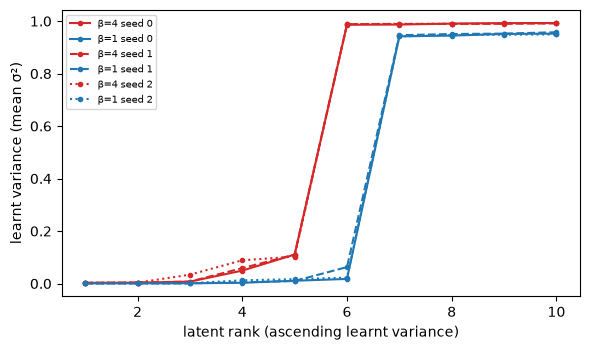

Per run, latents in Fig. 7 order: learnt variance | mean KL (nats) | top factor and its variance share

β=4 seed 0  (5 latents with KL >= 0.01 nats)
   z4   σ²=0.003  KL=3.080  top=posY     [shape=0.00 scale=0.00 rotation=0.00 posX=0.02 posY=0.76]
   z7   σ²=0.003  KL=3.042  top=posX     [shape=0.00 scale=0.00 rotation=0.00 posX=0.78 posY=0.01]
   z9   σ²=0.007  KL=2.554  top=posY     [shape=0.03 scale=0.12 rotation=0.00 posX=0.33 posY=0.38]
   z5   σ²=0.049  KL=1.792  top=rotation [shape=0.00 scale=0.00 rotation=0.17 posX=0.05 posY=0.05]
   z10  σ²=0.111  KL=1.255  top=rotation [shape=0.00 scale=0.00 rotation=0.22 posX=0.00 posY=0.00]
   z3   σ²=0.986  KL=0.000  top=posY     [shape=0.00 scale=0.01 rotation=0.01 posX=0.01 posY=0.02]
   z1   σ²=0.987  KL=0.000  top=posX     [shape=0.00 scale=0.00 rotation=0.01 posX=0.02 posY=0.01]
   z2   σ²=0.991  KL=0.000  top=posX     [shape=0.00 scale=0.00 rotation=0.00 posX=0.02 posY=0.01]
   z8   σ²=0.992  KL=0.000  top=posX     [shape=0.00 scale=

In [16]:
# The paper's "learnt variance" row for every run: sorted profile per seed
fig, ax = plt.subplots(figsize=(6, 3.6))
for beta, seed in RUN_ORDER:
    A = load_analysis(beta, seed)
    if A is None: continue
    ax.plot(np.arange(1, len(A["order"]) + 1), np.sort(A["learnt_variance"]), marker="o", ms=3,
            color="tab:red" if beta == 4.0 else "tab:blue", ls=["-", "--", ":"][seed % 3], label=f"β={beta:g} seed {seed}")
ax.set_xlabel("latent rank (ascending learnt variance)"); ax.set_ylabel("learnt variance (mean σ²)")
ax.legend(fontsize=7); plt.tight_layout(); fig.savefig(FIG_DIR / "learnt_variance_profiles.png", dpi=130); plt.show()

print("Per run, latents in Fig. 7 order: learnt variance | mean KL (nats) | top factor and its variance share\n")
for beta, seed in RUN_ORDER:
    rd = run_dir_for(beta, seed)
    if (rd / "FAILED.json").exists():
        print(f"β={beta:g} seed {seed}: FAILED {json.loads((rd / 'FAILED.json').read_text())}\n"); continue
    A = load_analysis(beta, seed)
    if A is None:
        print(f"β={beta:g} seed {seed}: no analysis\n"); continue
    n_active = int((A["kl_per_latent"] >= KL_INACTIVE_NATS).sum())
    print(f"β={beta:g} seed {seed}  ({n_active} latents with KL >= {KL_INACTIVE_NATS} nats)")
    for m in A["order"]:
        f = A["factor_fractions"][m]; j = int(np.argmax(f))
        shares = " ".join(f"{k}={v:.2f}" for k, v in zip(A["factor_keys"], f))
        print(f"   z{m + 1:<3d} σ²={A['learnt_variance'][m]:.3f}  KL={A['kl_per_latent'][m]:.3f}  top={A['factor_keys'][j]:<8s} [{shares}]")
    print()

In [17]:
# Compute actually used, from the saved files
train_s = sum(json.loads((run_dir_for(b, s) / "DONE.json").read_text())["train_seconds"]
              for b, s in RUN_ORDER if (run_dir_for(b, s) / "DONE.json").exists())
anal_s = sum(float(load_analysis(b, s)["analysis_seconds"]) for b, s in RUN_ORDER if load_analysis(b, s) is not None)
bench_s = PLAN.get("benchmark_seconds", 0.0)
print(f"training {train_s / 60:.1f} min + analysis {anal_s / 60:.1f} min + benchmark {bench_s / 60:.1f} min "
      f"= {(train_s + anal_s + bench_s) / 60:.1f} of {GPU_BUDGET_MIN:.0f} GPU-minutes "
      f"(excludes data loading, plotting, and any steps lost to interruptions)")

training 76.8 min + analysis 0.2 min + benchmark 0.1 min = 77.0 of 130 GPU-minutes (excludes data loading, plotting, and any steps lost to interruptions)


## 14. Reading the result

Compare the figures with the criteria stated in §3 before training. Three cautions apply however the figures look.

* **The column indices are arbitrary.** A given run's z₁…z₁₀ have no relation to the paper's z₁…z₁₀ or to another seed's; only the variance ordering and the response patterns are comparable.
* **Seed count limits.** With 3 seeds (or fewer, if `plan.json` says so) you can say whether the pattern recurs; you cannot estimate how often β = 4 fails or put an error bar on anything with useful precision (§3).
* **The unspecified choices matter.** Training length, batch size and the Adagrad details (U1–U3) are mine, not the paper's. If β = 4 does not separate the factors, under-training is the first thing to check: the per-latent KL curves show whether the set of active latents was still changing at the end.